In [1]:
import os, heapq
from math import factorial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

os.makedirs("results", exist_ok=True)

MEAN_SERVICE = 6.0   # average service time = 6 minutes
BASE_RATE = 0.40     # normal arrivals = 0.40 customers per minute
HORIZON = 480        # one working day = 480 minutes
N_NORMAL = 3         # counters on a normal day
ALPHA = 0.10         # we accept 10% broken promises
print("setup done")

setup done


In [2]:
def make_scenario(name, horizon=HORIZON):
    full_day = [(0, np.inf)] * N_NORMAL            # (open time, close time) of each counter

    if name == "S0_normal":                        # a normal day
        rate_fn = lambda t: BASE_RATE
        counters = full_day

    elif name == "S1_rush_hour":                   # 25% more customers from minute 180 to 300
        rate_fn = lambda t: BASE_RATE * (1.25 if 180 <= t < 300 else 1.0)
        counters = full_day

    elif name == "S2_counter_closes":              # counter 3 is closed from minute 240 to 360
        rate_fn = lambda t: BASE_RATE
        counters = [(0, np.inf), (0, np.inf), (0, 240), (360, np.inf)]

    elif name == "S3_slow_growth":                 # arrivals grow slowly to 1.25x by the end of the day
        rate_fn = lambda t: BASE_RATE * (1.0 + 0.25 * t / horizon)
        counters = full_day

    else:
        raise ValueError(name)

    return {"name": name, "rate_fn": rate_fn, "counters": counters, "horizon": horizon}

SCENARIOS = ["S0_normal", "S1_rush_hour", "S2_counter_closes", "S3_slow_growth"]
print("scenarios ready:", SCENARIOS)

scenarios ready: ['S0_normal', 'S1_rush_hour', 'S2_counter_closes', 'S3_slow_growth']


In [3]:
def generate_arrivals(rate_fn, horizon, rng):
    grid = np.linspace(0, horizon, 2000)
    rate_max = max(rate_fn(t) for t in grid) * 1.001
    arrivals, t = [], 0.0
    while True:
        t += rng.exponential(1.0 / rate_max)
        if t >= horizon:
            break
        if rng.random() < rate_fn(t) / rate_max:     # keep the arrival with probability rate(t)/rate_max
            arrivals.append(t)
    return np.array(arrivals)

rng = np.random.default_rng(0)
print("customers in one normal day:", len(generate_arrivals(lambda t: BASE_RATE, HORIZON, rng)))

customers in one normal day: 177


In [4]:
def simulate(scenario, seed=0, service_cv=1.0):
    rng = np.random.default_rng(seed)
    arrivals = generate_arrivals(scenario["rate_fn"], scenario["horizon"], rng)
    if service_cv == 1.0:
        service_times = rng.exponential(MEAN_SERVICE, size=len(arrivals))
    else:
        service_times = rng.gamma(1.0 / service_cv ** 2, MEAN_SERVICE * service_cv ** 2, size=len(arrivals))

    counters = scenario["counters"]
    free_at = [0.0] * len(counters)     # when each counter becomes free
    pending = []                        # start times of people still waiting
    rows = []

    for a, s in zip(arrivals, service_times):
        while pending and pending[0] <= a:          # remove people who already started service
            heapq.heappop(pending)

        queue_len = len(pending)                     # people waiting ahead of this customer
        open_now = sum(1 for (o, c) in counters if o <= a < c)
        idle = any((o <= a < c) and free_at[k] <= a for k, (o, c) in enumerate(counters))

        best_start, best_k = np.inf, None            # counter that can start this customer first
        for k, (o, c) in enumerate(counters):
            st = max(a, free_at[k], o)
            if st < c and st < best_start:
                best_start, best_k = st, k

        free_at[best_k] = best_start + s
        heapq.heappush(pending, best_start)

        rows.append({"arrival": a, "queue_len": queue_len, "open_counters": open_now,
                     "free": bool(idle),             # True = a counter was free, so no waiting
                     "service_time": s, "start": best_start, "wait": best_start - a})
    return pd.DataFrame(rows)

day = simulate(make_scenario("S0_normal"), seed=0)
day.head(8).round(2)

,arrival,queue_len,open_counters,free,service_time,start,wait
0,1.70,0,3,True,5.53,1.70,0.0
1,1.75,0,3,True,1.02,1.75,0.0
2,3.12,0,3,True,0.27,3.12,0.0
3,4.80,0,3,True,0.04,4.80,0.0
4,11.84,0,3,True,10.34,11.84,0.0
5,20.05,0,3,True,0.52,20.05,0.0
6,25.71,0,3,True,8.85,25.71,0.0
7,28.39,0,3,True,0.34,28.39,0.0


In [5]:
def erlang_c_mean_wait(lam, mean_service, c):
    mu = 1.0 / mean_service
    a = lam / mu
    rho = a / c
    top = a ** c / factorial(c) / (1 - rho)
    bottom = sum(a ** k / factorial(k) for k in range(c)) + top
    return (top / bottom) / (c * mu - lam)

sims = []
for seed in range(5):
    d = simulate(make_scenario("S0_normal", horizon=100000), seed=seed)
    d = d[d.arrival > 2000]                     # ignore the first 2000 minutes (queue starts empty)
    sims.append(d.wait.mean())

print("Simulated average wait:", round(np.mean(sims), 2), "minutes")
print("Theory (Erlang C)     :", round(erlang_c_mean_wait(BASE_RATE, MEAN_SERVICE, N_NORMAL), 2), "minutes")

Simulated average wait: 6.54 minutes
Theory (Erlang C)     : 6.47 minutes


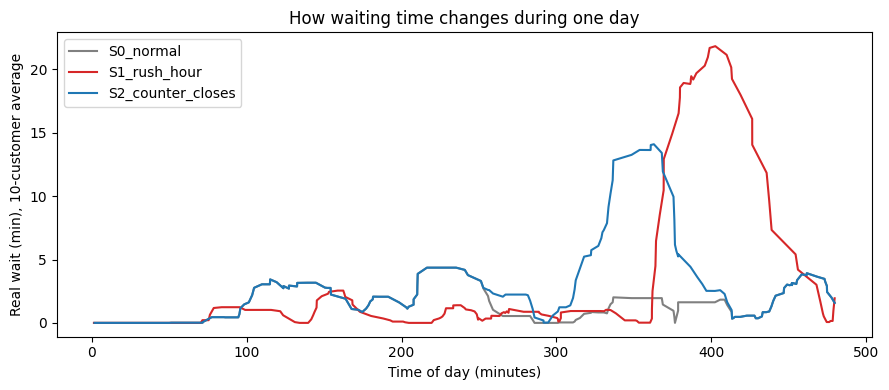

In [6]:
plt.figure(figsize=(9, 4))
for name, col in [("S0_normal", "gray"), ("S1_rush_hour", "tab:red"), ("S2_counter_closes", "tab:blue")]:
    dd = simulate(make_scenario(name), seed=0)
    plt.plot(dd["arrival"], dd["wait"].rolling(10, min_periods=1).mean(), label=name, color=col)
plt.xlabel("Time of day (minutes)"); plt.ylabel("Real wait (min), 10-customer average")
plt.title("How waiting time changes during one day"); plt.legend(); plt.tight_layout()
plt.savefig("results/fig1_waiting_time.png", dpi=120); plt.show()

In [7]:
TRAIN_SEEDS = range(5000, 5100)       # training days
CALIB_SEEDS = range(1000, 1050)       # days used to set the starting margin
TUNE_SEEDS  = range(3000, 3040)       # days used to choose settings
TEST_SEEDS  = range(100, 200)         # final test days (never used for tuning)

def fit_rule(service_cv=1.0):
    train = pd.concat([simulate(make_scenario("S0_normal"), seed=s, service_cv=service_cv) for s in TRAIN_SEEDS])
    train = train[~train["free"]]                  # when a counter is free, we simply announce "now"
    lr = LinearRegression().fit(train[["queue_len"]], train["wait"])
    return lr.intercept_, lr.coef_[0]

RULE = fit_rule()
print("Learned rule: wait = %.2f + %.2f x people_ahead" % RULE)

def base_prediction(queue_len, rule=None):
    a0, b0 = rule if rule is not None else RULE
    return max(a0 + b0 * queue_len, 0.0)

# Does this predictor fail when a counter closes?  (real wait minus predicted wait)
for sc in SCENARIOS:
    errs = []
    for s in range(40):
        d = simulate(make_scenario(sc), seed=s)
        d = d[~d["free"]]
        errs.append((d["wait"] - d["queue_len"].map(base_prediction)).mean())
    print(f"{sc:20s} average (real - predicted) = {np.mean(errs):+.2f} min")

Learned rule: wait = 1.93 + 2.02 x people_ahead
S0_normal            average (real - predicted) = -0.31 min
S1_rush_hour         average (real - predicted) = -0.45 min
S2_counter_closes    average (real - predicted) = +1.38 min
S3_slow_growth       average (real - predicted) = -0.40 min


In [8]:
class Announcer:
    def __init__(self, method, m0, z0=None, eta=0.5, eta_z=0.05, alpha=ALPHA, boost=4.0, boost_n=20,
                 recal_every=50, window=100):
        self.method, self.eta, self.eta_z, self.alpha = method, eta, eta_z, alpha
        self.boost, self.boost_n = boost, boost_n
        self.recal_every, self.window = recal_every, window
        self.correction = method in ("M5", "M6", "M5+boost")                  # event-aware correction
        self.scaled = method in ("M4s", "M6")                                  # margin grows with line length
        self.boost_on = method.endswith("+boost")                              # faster learning after an event
        self.adaptive = method in ("M4", "M4s", "M5", "M6", "M4+boost", "M5+boost")
        self.m = z0 if self.scaled else m0                                     # current margin (or scale factor z)
        self.boost_left, self.prev_open, self.count, self.resid = 0, N_NORMAL, 0, []

    def _scale(self, p_adj):
        return np.sqrt(max(p_adj, 1.0)) if self.scaled else 1.0

    def announce(self, p, free, open_now):
        # known event: the number of open counters changed
        if open_now != self.prev_open:
            if self.boost_on:
                self.boost_left = self.boost_n
            self.prev_open = open_now
        self.count += 1

        # M3: recalculate the margin every 50 customers from recent errors
        if self.method == "M3" and self.count % self.recal_every == 0 and len(self.resid) >= 30:
            self.m = max(0.0, float(np.quantile(self.resid[-self.window:], 1 - self.alpha)))

        # event-aware correction: fewer counters open than on a normal day
        p_adj = p
        if self.correction and 0 < open_now < N_NORMAL:
            p_adj = p * N_NORMAL / open_now

        if free:                                   # a counter is free: announce "now"
            result = (0.0, 0.0, 0.0)
        else:
            m = 0.0 if self.method == "M1" else self.m * self._scale(p_adj)
            result = (p_adj + m, m, p_adj)         # announced wait, margin used, corrected prediction

        if self.boost_left > 0:
            self.boost_left -= 1
        return result

    def observe(self, wait, p_adj):
        # called when we learn how long a customer really waited
        if self.method == "M3":
            self.resid.append(wait - p_adj)
        elif self.adaptive:
            broken = 1.0 if wait > p_adj + self.m * self._scale(p_adj) else 0.0
            step = self.eta_z if self.scaled else self.eta
            if self.boost_left > 0:
                step *= self.boost
            self.m = max(0.0, self.m + step * (broken - self.alpha))
print("Announcer ready")

Announcer ready


In [9]:
def run_announcements(d, ann, rule=None):
    arr, st, w = d["arrival"].values, d["start"].values, d["wait"].values
    q, oc, fr = d["queue_len"].values, d["open_counters"].values, d["free"].values
    n = len(d)
    A, M, P = np.zeros(n), np.zeros(n), np.zeros(n)
    ptr = 0
    for i in range(n):
        while ptr < i and st[ptr] <= arr[i]:        # customers whose service has started: we learn their wait
            if not fr[ptr]:
                ann.observe(w[ptr], P[ptr])
            ptr += 1
        A[i], M[i], P[i] = ann.announce(base_prediction(q[i], rule), fr[i], oc[i])
    out = d.copy()
    out["announced"], out["margin"], out["p_adj"] = A, M, P
    out["broken"] = (out["wait"] > out["announced"] + 1e-9) & (~out["free"])
    return out

demo = run_announcements(simulate(make_scenario("S2_counter_closes"), seed=0), Announcer("M1", 0.0))
demo[~demo["free"]][["arrival", "queue_len", "announced", "wait", "broken"]].head(8).round(2)

,arrival,queue_len,announced,wait,broken
16,51.32,0,1.93,0.13,False
23,71.75,0,1.93,0.60,False
24,77.45,0,1.93,3.78,True
31,95.30,0,1.93,2.44,True
32,95.93,1,3.95,4.77,True
33,98.42,1,3.95,3.63,False
34,101.38,1,3.95,5.34,True
35,103.54,1,3.95,5.68,True


In [10]:
def calibrate_margins(rule, service_cv=1.0):
    # starting margins: the 90th percentile of the prediction error on normal days
    res, resz = [], []
    for s in CALIB_SEEDS:
        d = simulate(make_scenario("S0_normal"), seed=s, service_cv=service_cv)
        d = d[~d["free"]]
        p = d["queue_len"].map(lambda q: base_prediction(q, rule))
        res.extend((d["wait"] - p).tolist())                              # for fixed margins (minutes)
        resz.extend(((d["wait"] - p) / np.sqrt(np.maximum(p, 1.0))).tolist())   # for scaled margins
    return max(0.0, float(np.quantile(res, 1 - ALPHA))), max(0.0, float(np.quantile(resz, 1 - ALPHA)))

m0, z0 = calibrate_margins(RULE)
print("Starting margin m0 = %.2f minutes, starting scale z0 = %.2f" % (m0, z0))

def broken_rate(sc, method, seeds, **kw):
    vals = []
    for s in seeds:
        out = run_announcements(simulate(make_scenario(sc), seed=s), Announcer(method, m0, z0, **kw))
        vals.append(out[~out["free"]]["broken"].mean())
    return np.mean(vals)

tune_scenarios = ["S0_normal", "S1_rush_hour", "S2_counter_closes"]

print("\nM4: eta   distance from the 10% target (smaller is better)")
scores = {}
for eta in [0.1, 0.25, 0.5, 1.0, 2.0]:
    scores[eta] = np.mean([abs(broken_rate(sc, "M4", TUNE_SEEDS, eta=eta) - ALPHA) for sc in tune_scenarios])
    print(f"  {eta:<5} {scores[eta]:.4f}")
ETA = min(scores, key=scores.get)

print("\nM6: eta_z   distance from the 10% target (smaller is better)")
scores_z = {}
for ez in [0.02, 0.05, 0.1, 0.2, 0.4]:
    scores_z[ez] = np.mean([abs(broken_rate(sc, "M6", TUNE_SEEDS, eta_z=ez) - ALPHA) for sc in tune_scenarios])
    print(f"  {ez:<5} {scores_z[ez]:.4f}")
ETAZ = min(scores_z, key=scores_z.get)
print("\nChosen: eta =", ETA, " eta_z =", ETAZ)

def new_ann(method):
    return Announcer(method, m0, z0, eta=ETA, eta_z=ETAZ)

Starting margin m0 = 4.86 minutes, starting scale z0 = 1.86

M4: eta   distance from the 10% target (smaller is better)
  0.1   0.0452
  0.25  0.0431
  0.5   0.0428
  1.0   0.0504
  2.0   0.0612

M6: eta_z   distance from the 10% target (smaller is better)
  0.02  0.0037
  0.05  0.0023
  0.1   0.0045
  0.2   0.0107
  0.4   0.0237

Chosen: eta = 0.5  eta_z = 0.05


In [11]:
WINDOWS = {"S0_normal": (240, 360), "S1_rush_hour": (180, 300),
           "S2_counter_closes": (240, 360), "S3_slow_growth": (240, 480)}
METHODS = ["M1", "M2", "M3", "M4", "M5", "M6"]

DAYS = {sc: [simulate(make_scenario(sc), seed=s) for s in TEST_SEEDS] for sc in SCENARIOS}

def day_metrics(out, window):
    nf = out[~out["free"]]
    w = nf[(nf["arrival"] >= window[0]) & (nf["arrival"] < window[1])]
    return {"broken": nf["broken"].mean(), "margin": nf["margin"].mean(),
            "broken_in_shift": w["broken"].mean() if len(w) else np.nan}

def ci95(x):
    x = np.array(x, dtype=float); x = x[~np.isnan(x)]
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))

RESULTS = {}      # per-day results, reused in later cells
rows = []
for sc in SCENARIOS:
    for mth in METHODS:
        per_day = [day_metrics(run_announcements(d, new_ann(mth)), WINDOWS[sc]) for d in DAYS[sc]]
        df_ = pd.DataFrame(per_day); RESULTS[(sc, mth)] = df_
        rows.append({"scenario": sc, "method": mth,
                     "broken %": f"{100*df_['broken'].mean():.1f} +/- {100*ci95(df_['broken']):.1f}",
                     "broken % in shift window": f"{100*df_['broken_in_shift'].mean():.1f} +/- {100*ci95(df_['broken_in_shift']):.1f}",
                     "avg margin (min)": f"{df_['margin'].mean():.2f}"})
main_table = pd.DataFrame(rows)
main_table.to_csv("results/main_results.csv", index=False)
main_table

,scenario,method,broken %,broken % in shift window,avg margin (min)
0,S0_normal,M1,41.9 +/- 1.8,38.1 +/- 3.5,0.00
1,S0_normal,M2,11.0 +/- 1.7,9.0 +/- 2.6,4.86
2,S0_normal,M3,12.8 +/- 1.3,12.0 +/- 2.8,4.76
3,S0_normal,M4,11.6 +/- 1.1,9.9 +/- 2.4,4.88
4,S0_normal,M5,11.6 +/- 1.1,9.9 +/- 2.4,4.88
5,S0_normal,M6,10.9 +/- 0.9,9.8 +/- 2.0,5.20
6,S1_rush_hour,M1,44.1 +/- 1.9,43.9 +/- 3.1,0.00
7,S1_rush_hour,M2,13.2 +/- 2.0,13.6 +/- 2.8,4.86
8,S1_rush_hour,M3,14.6 +/- 1.4,16.3 +/- 2.9,5.16
9,S1_rush_hour,M4,13.4 +/- 1.2,15.5 +/- 2.4,5.28


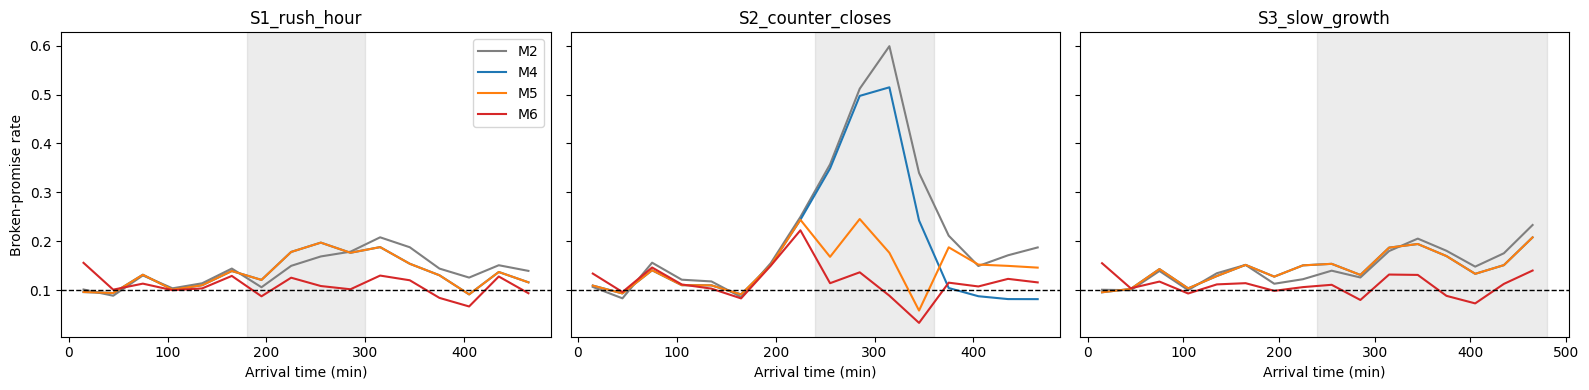

In [12]:
bins = np.arange(0, 481, 30)

def binned_curve(sc, mth):
    broken, total = np.zeros(len(bins) - 1), np.zeros(len(bins) - 1)
    for d in DAYS[sc]:
        out = run_announcements(d, new_ann(mth))
        nf = out[~out["free"]]
        idx = np.digitize(nf["arrival"].values, bins) - 1
        for k in range(len(bins) - 1):
            sel = idx == k
            broken[k] += nf["broken"].values[sel].sum(); total[k] += sel.sum()
    return broken / np.maximum(total, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
colors = {"M2": "tab:gray", "M4": "tab:blue", "M5": "tab:orange", "M6": "tab:red"}
for ax, sc in zip(axes, ["S1_rush_hour", "S2_counter_closes", "S3_slow_growth"]):
    for mth in ["M2", "M4", "M5", "M6"]:
        ax.plot(bins[:-1] + 15, binned_curve(sc, mth), label=mth, color=colors[mth])
    ax.axhline(ALPHA, color="black", linestyle="--", linewidth=1)
    ax.axvspan(*WINDOWS[sc], color="gray", alpha=0.15)
    ax.set_title(sc); ax.set_xlabel("Arrival time (min)")
axes[0].set_ylabel("Broken-promise rate"); axes[0].legend()
plt.tight_layout(); plt.savefig("results/fig2_broken_over_day.png", dpi=120); plt.show()

In [13]:
rows = []
for mth in ["M4", "M4s", "M5", "M6", "M4+boost", "M5+boost"]:
    per_day = [day_metrics(run_announcements(d, new_ann(mth)), WINDOWS["S2_counter_closes"])
               for d in DAYS["S2_counter_closes"]]
    df_ = pd.DataFrame(per_day)
    rows.append({"method": mth,
                 "broken %": round(100 * df_["broken"].mean(), 1),
                 "broken % in shift": round(100 * df_["broken_in_shift"].mean(), 1),
                 "avg margin (min)": round(df_["margin"].mean(), 2)})
ablation = pd.DataFrame(rows)
print(ablation.to_string(index=False))
ablation.to_csv("results/ablation_S2.csv", index=False)

print("\nPaired differences over 100 days (percentage points, positive = second method is better)")
rows = []
for sc in SCENARIOS:
    r = {"scenario": sc}
    for label, (a, b) in {"correction (M4 - M5)": ("M4", "M5"),
                          "length scaling (M5 - M6)": ("M5", "M6"),
                          "total (M4 - M6)": ("M4", "M6")}.items():
        diff = RESULTS[(sc, a)]["broken"] - RESULTS[(sc, b)]["broken"]
        r[label] = f"{100*diff.mean():.1f} +/- {100*ci95(diff):.1f}"
    rows.append(r)
paired = pd.DataFrame(rows)
paired.to_csv("results/paired_differences.csv", index=False)
print(paired.to_string(index=False))

  method  broken %  broken % in shift  avg margin (min)
      M4      19.5               37.9              6.81
     M4s      17.2               31.8              7.49
      M5      14.3               15.3              5.38
      M6      11.0                9.1              7.23
M4+boost      18.5               34.6              7.28
M5+boost      14.8               15.0              5.50

Paired differences over 100 days (percentage points, positive = second method is better)
         scenario correction (M4 - M5) length scaling (M5 - M6) total (M4 - M6)
        S0_normal          0.0 +/- 0.0              0.7 +/- 0.6     0.7 +/- 0.6
     S1_rush_hour          0.0 +/- 0.0              3.1 +/- 0.7     3.1 +/- 0.7
S2_counter_closes          5.2 +/- 0.8              3.2 +/- 0.6     8.5 +/- 1.1
   S3_slow_growth          0.0 +/- 0.0              4.0 +/- 0.7     4.0 +/- 0.7


In [14]:
groups = [("1-2 ahead", 1, 2), ("3-5 ahead", 3, 5), ("6+ ahead", 6, 1000)]
rows = []
for mth in ["M2", "M4", "M5", "M6"]:
    counts = {g[0]: [0, 0] for g in groups}
    for sc in SCENARIOS:
        for d in DAYS[sc][:40]:
            out = run_announcements(d, new_ann(mth))
            nf = out[~out["free"]]
            for g, lo, hi in groups:
                sel = (nf["queue_len"] >= lo) & (nf["queue_len"] <= hi)
                counts[g][0] += nf["broken"][sel].sum(); counts[g][1] += sel.sum()
    row = {"method": mth}
    for g, _, _ in groups:
        row[g] = f"{100 * counts[g][0] / max(counts[g][1], 1):.1f}%"
    rows.append(row)
strata = pd.DataFrame(rows); strata.to_csv("results/reliability_by_line_length.csv", index=False)
strata

,method,1-2 ahead,3-5 ahead,6+ ahead
0,M2,9.3%,15.8%,27.0%
1,M4,11.4%,17.5%,21.0%
2,M5,11.2%,16.3%,18.1%
3,M6,11.8%,11.3%,9.3%


In [15]:
rows = []
for cv in [0.5, 1.0, 1.5]:
    rule_cv = fit_rule(cv)
    m0_cv, z0_cv = calibrate_margins(rule_cv, cv)
    for sc in ["S0_normal", "S1_rush_hour", "S2_counter_closes"]:
        days = [simulate(make_scenario(sc), seed=s, service_cv=cv) for s in list(TEST_SEEDS)[:60]]
        row = {"service variability (CV)": cv, "scenario": sc}
        for mth in ["M4", "M5", "M6"]:
            vals = [run_announcements(d, Announcer(mth, m0_cv, z0_cv, eta=ETA, eta_z=ETAZ), rule_cv)
                    .query("~free")["broken"].mean() for d in days]
            row[mth + " broken %"] = f"{100*np.mean(vals):.1f} +/- {100*ci95(vals):.1f}"
        rows.append(row)
robust = pd.DataFrame(rows); robust.to_csv("results/robustness_service_variability.csv", index=False)
robust

,service variability (CV),scenario,M4 broken %,M5 broken %,M6 broken %
0,0.5,S0_normal,11.7 +/- 0.7,11.7 +/- 0.7,10.4 +/- 0.6
1,0.5,S1_rush_hour,12.2 +/- 0.8,12.2 +/- 0.8,9.3 +/- 0.6
2,0.5,S2_counter_closes,21.0 +/- 1.5,13.9 +/- 1.1,9.4 +/- 0.8
3,1.0,S0_normal,11.0 +/- 1.3,11.0 +/- 1.3,10.2 +/- 1.2
4,1.0,S1_rush_hour,12.5 +/- 1.3,12.5 +/- 1.3,9.5 +/- 1.0
5,1.0,S2_counter_closes,19.1 +/- 2.1,13.6 +/- 1.6,10.5 +/- 1.2
6,1.5,S0_normal,11.5 +/- 1.7,11.5 +/- 1.7,10.1 +/- 1.3
7,1.5,S1_rush_hour,13.1 +/- 2.2,13.1 +/- 2.2,10.3 +/- 1.5
8,1.5,S2_counter_closes,19.2 +/- 2.2,14.3 +/- 1.9,10.8 +/- 1.4


In [16]:
def simulate_balking(scenario, ann, seed=0, announce=True,
                     balk_start=10.0, balk_slope=1/40, balk_max=0.8):
    # leaving rule: no one leaves if the announced wait is <= 10 min; 25% leave at 20 min; 50% at 30 min; max 80%
    rng = np.random.default_rng(seed)
    arrivals = generate_arrivals(scenario["rate_fn"], scenario["horizon"], rng)
    service_times = rng.exponential(MEAN_SERVICE, size=len(arrivals))
    u = rng.random(len(arrivals))                 # same randomness for every method (fair comparison)

    counters = scenario["counters"]
    free_at = [0.0] * len(counters)
    pending, joined, ptr, rows = [], [], 0, []

    for i, a in enumerate(arrivals):
        while ptr < len(joined) and joined[ptr][0] <= a:      # learn from customers who started service
            if not joined[ptr][3]:
                ann.observe(joined[ptr][1], joined[ptr][2])
            ptr += 1
        while pending and pending[0] <= a:
            heapq.heappop(pending)

        queue_len = len(pending)
        open_now = sum(1 for (o, c) in counters if o <= a < c)
        idle = any((o <= a < c) and free_at[k] <= a for k, (o, c) in enumerate(counters))

        A, M, P = ann.announce(base_prediction(queue_len), idle, open_now)
        p_balk = 0.0
        if announce and not idle:
            p_balk = min(max((A - balk_start) * balk_slope, 0.0), balk_max)

        if u[i] < p_balk:                                     # this customer leaves
            rows.append({"arrival": a, "announced": A, "margin": M, "free": idle,
                         "balked": True, "wait": np.nan, "broken": False})
            continue

        best_start, best_k = np.inf, None
        for k, (o, c) in enumerate(counters):
            st = max(a, free_at[k], o)
            if st < c and st < best_start:
                best_start, best_k = st, k
        free_at[best_k] = best_start + service_times[i]
        heapq.heappush(pending, best_start)
        wait = best_start - a
        joined.append((best_start, wait, P, idle))
        rows.append({"arrival": a, "announced": A, "margin": M, "free": idle, "balked": False,
                     "wait": wait, "broken": (wait > A + 1e-9) and (not idle)})
    return pd.DataFrame(rows)
print("balking simulator ready")

balking simulator ready


In [17]:
rows = []
for sc in ["S1_rush_hour", "S2_counter_closes"]:
    for mth in ["none", "M1", "M2", "M4", "M5", "M6"]:
        per_day = []
        for s in TEST_SEEDS:
            ann = new_ann("M1" if mth == "none" else mth)
            o = simulate_balking(make_scenario(sc), ann, seed=s, announce=(mth != "none"))
            served = o[~o["balked"]]; nf = served[~served["free"]]
            per_day.append({"customers who left %": 100 * o["balked"].mean(),
                            "avg wait of served (min)": served["wait"].mean(),
                            "customers served": len(served),
                            "broken %": 100 * nf["broken"].mean() if mth != "none" else np.nan,
                            "avg margin (min)": nf["margin"].mean()})
        r = pd.DataFrame(per_day).mean().round(2)
        rows.append({"scenario": sc, "method": mth, **r.to_dict()})
balk_table = pd.DataFrame(rows); balk_table.to_csv("results/balking_results.csv", index=False)
balk_table

,scenario,method,customers who left %,avg wait of served (min),customers served,broken %,avg margin (min)
0,S1_rush_hour,none,0.00,10.21,203.86,NaN,0.00
1,S1_rush_hour,M1,3.69,6.01,196.04,43.76,0.00
2,S1_rush_hour,M2,5.72,4.72,191.88,10.09,4.86
3,S1_rush_hour,M4,5.73,4.68,191.83,11.27,4.71
4,S1_rush_hour,M5,5.73,4.68,191.83,11.27,4.71
5,S1_rush_hour,M6,6.19,4.39,190.90,10.66,4.60
6,S2_counter_closes,none,0.00,12.85,191.52,NaN,0.00
7,S2_counter_closes,M1,4.57,7.30,182.46,51.62,0.00
8,S2_counter_closes,M2,6.39,5.70,178.97,17.62,4.86
9,S2_counter_closes,M4,7.29,5.38,177.21,16.44,5.66


In [18]:
parts = []
for d in DAYS["S2_counter_closes"]:
    out = run_announcements(d, new_ann("M6"))
    parts.append(out[~out["free"]])
allc = pd.concat(parts)

print("M6 broken-promise rate by arrival time (counter closes at minute 240, reopens at 360)")
for lo, hi in [(180, 210), (210, 240), (240, 270), (270, 360), (360, 420), (420, 480)]:
    sel = allc[(allc["arrival"] >= lo) & (allc["arrival"] < hi)]
    print(f"  arrived {lo:3d}-{hi:3d} min: {100*sel['broken'].mean():5.1f}%   (n={len(sel)})")

worst = allc.assign(minutes_late=allc["wait"] - allc["announced"]).sort_values("minutes_late", ascending=False)
worst[["arrival", "queue_len", "announced", "wait", "minutes_late"]].head(5).round(1)

M6 broken-promise rate by arrival time (counter closes at minute 240, reopens at 360)
  arrived 180-210 min:  15.0%   (n=754)
  arrived 210-240 min:  22.2%   (n=697)
  arrived 240-270 min:  11.4%   (n=946)
  arrived 270-360 min:   8.5%   (n=3360)
  arrived 360-420 min:  11.1%   (n=2144)
  arrived 420-480 min:  11.9%   (n=2009)


,arrival,queue_len,announced,wait,minutes_late
115,223.0,19,49.7,90.0,40.4
122,235.4,23,58.6,98.5,39.9
119,231.4,23,58.7,97.0,38.4
121,235.2,22,56.3,94.5,38.1
118,230.8,22,56.4,94.3,37.9


In [19]:
import shutil
shutil.make_archive("results", "zip", "results")
print(sorted(os.listdir("results")))
try:
    from google.colab import files
    files.download("results.zip")          # works in Colab
except Exception:
    print("results.zip created (download it from the file panel)")

['ablation_S2.csv', 'balking_results.csv', 'fig1_waiting_time.png', 'fig2_broken_over_day.png', 'main_results.csv', 'paired_differences.csv', 'reliability_by_line_length.csv', 'robustness_service_variability.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>